In [1]:
# Step 1: Import required libraries
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
# Step 2: Download and load the dataset
path = kagglehub.dataset_download("yasserh/uber-fares-dataset")
df = pd.read_csv(path + "/uber.csv")

df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
print("Original Dataset Shape:", df.shape)

Original Dataset Shape: (200000, 9)


In [4]:
# Step 3: Remove missing values, duplicates and unnecessary columns
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)

# Convert pickup date and extract time features
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)
df.dropna(subset=["pickup_datetime"], inplace=True)

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek

df.drop(columns=["pickup_datetime"], inplace=True)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 11 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   fare_amount        199999 non-null  float64
 1   pickup_longitude   199999 non-null  float64
 2   pickup_latitude    199999 non-null  float64
 3   dropoff_longitude  199999 non-null  float64
 4   dropoff_latitude   199999 non-null  float64
 5   passenger_count    199999 non-null  int64  
 6   hour               199999 non-null  int32  
 7   day                199999 non-null  int32  
 8   month              199999 non-null  int32  
 9   year               199999 non-null  int32  
 10  dayofweek          199999 non-null  int32  
dtypes: float64(5), int32(5), int64(1)
memory usage: 14.5 MB


In [5]:
# Step 4: Calculate distance using the Haversine formula
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(
    df["pickup_latitude"], df["pickup_longitude"],
    df["dropoff_latitude"], df["dropoff_longitude"]
)

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


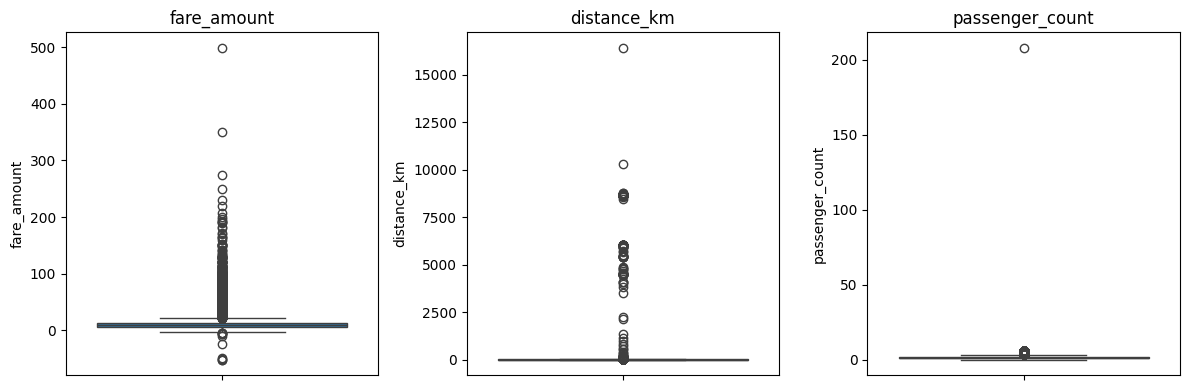

In [6]:
# Step 5: Display boxplots to identify outliers
plt.figure(figsize=(12, 4))

for i, col in enumerate(["fare_amount", "distance_km", "passenger_count"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [7]:
# Step 6: Remove unrealistic fares, distances and coordinates
df = df[
    (df["fare_amount"].between(2.5, 100)) &
    (df["distance_km"].between(0.1, 100)) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_latitude"].between(40, 42)) &
    (df["dropoff_longitude"].between(-75, -72))
].copy()

df.reset_index(drop=True, inplace=True)
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (191842, 12)


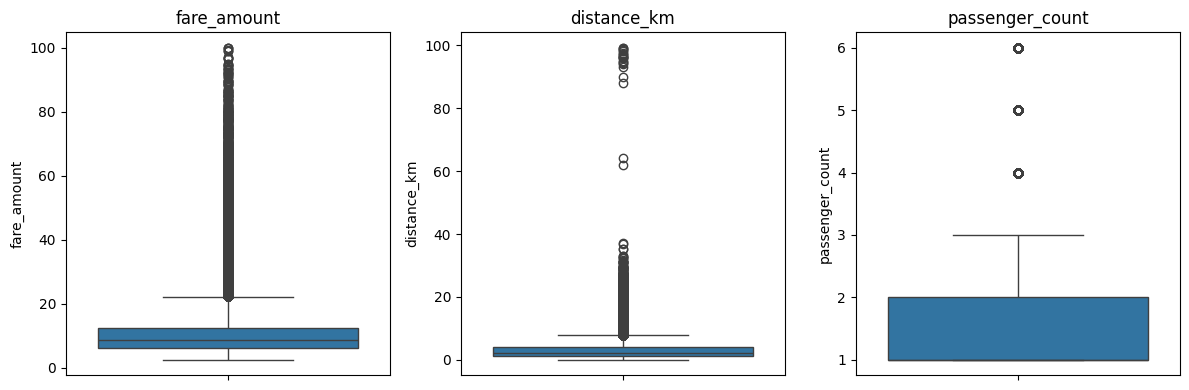

In [8]:
# Step 7: Check outliers after cleaning
plt.figure(figsize=(12, 4))

for i, col in enumerate(["fare_amount", "distance_km", "passenger_count"]):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

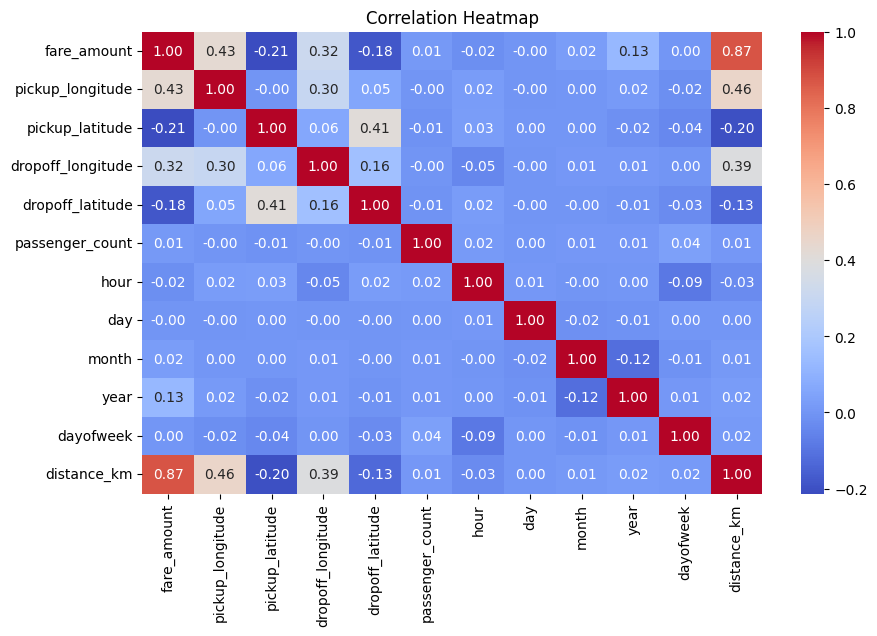

fare_amount          1.000000
distance_km          0.872306
pickup_longitude     0.426951
dropoff_longitude    0.315586
year                 0.125287
month                0.024869
passenger_count      0.014324
dayofweek            0.004544
day                 -0.000084
hour                -0.020305
dropoff_latitude    -0.182715
pickup_latitude     -0.213080
Name: fare_amount, dtype: float64


In [9]:
# Step 8: Display correlations between numerical features
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print(df.corr(numeric_only=True)["fare_amount"].sort_values(ascending=False))

In [10]:
# Step 9: Select features and split the dataset
features = [
    "distance_km", "passenger_count", "hour",
    "day", "month", "year", "dayofweek"
]

X = df[features]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale features for Linear Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (153473, 7)
Testing data: (38369, 7)


In [11]:
# Step 10: Train and evaluate Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("Linear Regression")
print("R2 Score:", r2_score(y_test, lr_pred))
print("MSE:", mean_squared_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("MAE:", mean_absolute_error(y_test, lr_pred))

Linear Regression
R2 Score: 0.7655303545303929
MSE: 20.332382170933485
RMSE: 4.509144283667744
MAE: 2.2007067608889037


In [12]:
# Step 11: Train and evaluate Random Forest
rf = RandomForestRegressor(
    n_estimators=50, max_depth=15, n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Regression")
print("R2 Score:", r2_score(y_test, rf_pred))
print("MSE:", mean_squared_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("MAE:", mean_absolute_error(y_test, rf_pred))

Random Forest Regression
R2 Score: 0.8561726009056326
MSE: 12.472205684369136
RMSE: 3.531601008660114
MAE: 1.959068197581364


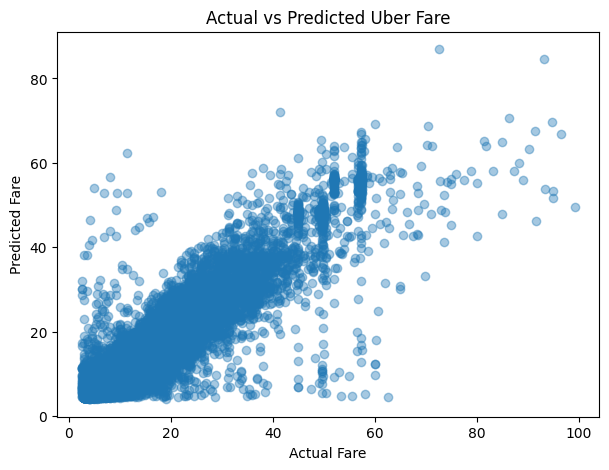

In [13]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, rf_pred, alpha=0.4)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fare")
plt.show()

In [14]:
# Step 12: Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, rf_pred)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.765530  4.509144  2.200707
1      Random Forest  0.856173  3.531601  1.959068


In [15]:
# Step 13: Predict fare for a sample ride
sample = pd.DataFrame([{
    "distance_km": 5.5,
    "passenger_count": 2,
    "hour": 18,
    "day": 15,
    "month": 8,
    "year": 2014,
    "dayofweek": 4
}])

lr_fare = lr.predict(scaler.transform(sample))[0]
rf_fare = rf.predict(sample)[0]

print("Linear Regression Fare:", round(lr_fare, 2))
print("Random Forest Fare:", round(rf_fare, 2))

Linear Regression Fare: 17.32
Random Forest Fare: 18.88
